# <b><span style='color:#F1A424'>AutoML - Multiclass Classification - BMI Value Prediction </span> </b>

### Disclaimer
The sample code (“Sample Code”) provided is not covered by any Teradata agreements. Please be aware that Teradata has no control over the model responses to such sample code and such response may vary. The use of the model by Teradata is strictly for demonstration purposes and does not constitute any form of certification or endorsement. The sample code is provided “AS IS” and any express or implied warranties, including the implied warranties of merchantability and fitness for a particular purpose, are disclaimed. In no event shall Teradata be liable for any direct, indirect, incidental, special, exemplary, or consequential damages (including, but not limited to, procurement of substitute goods or services; loss of use, data, or profits; or business interruption) sustained by you or a third party, however caused and on any theory of liability, whether in contract, strict liability, or tort arising in any way out of the use of this sample code, even if advised of the possibility of such damage.

## <b> Problem overview:</b>
    

**Dataset used: BMI Dataset**

**Features**:

- `gender`: Gender of person.
- `height`: Height of person.
- `weight`: Weight of person.

**Target Variable**:

- `bmi`: BMI value of person.

        
**Objective**:

The primary objective is typically to build a model that can accurately predict BMI of person.

**Usecase**:

Here, we will use AutoML(Automated Machine Learning) functionality to automate the entire process of developing a predictive model. It will perform feature exploration, feature engineering, data preparation, model training and evaluation on dataset in auto run and at end we will get leaderboard containined different models along with their performance. Model will also have rank associated with them which indicates which is best performing model for given data followed by other models.

In [1]:
# Importing other important libraries
import getpass
from teradataml import create_context, display

display.enable_ui = False

In [2]:
# Create the connection.
host = getpass.getpass("Host: ")
username = getpass.getpass("Username: ")
password = getpass.getpass("Password: ")

ctx = create_context(host=host, username=username, password=password)

## <b><span style='color:#F1A424'>| 1.</span> Loading Deployed Models - 'BMI_top_3_models' </b>

### <b><span style='color:#F1A424'>| 1.1.</span> Loading Model </b>

In [3]:
# Creating AutoML object

aml=ctx.AutoML()

In [4]:
# Loading models

models_1 = aml.load('BMI_top_3_models')

In [5]:
# Display loaded models


models_1

,RANK,MODEL_ID,FEATURE_SELECTION,ACCURACY,MICRO-PRECISION,MICRO-RECALL,MICRO-F1,MACRO-PRECISION,MACRO-RECALL,MACRO-F1,WEIGHTED-PRECISION,WEIGHTED-RECALL,WEIGHTED-F1,DATA_TABLE
0,1,XGBOOST_0,rfe,0.727273,0.727273,0.727273,0.727273,0.699009,0.693182,0.694945,0.729955,0.727273,0.727593,automl__bmi_rfe_179282104223055
1,2,XGBOOST_3,pca,0.727273,0.727273,0.727273,0.727273,0.793245,0.676818,0.690056,0.773201,0.727273,0.723600,automl__bmi_pca_179280906339003
2,3,XGBOOST_2,rfe,0.636364,0.636364,0.636364,0.636364,0.604762,0.543636,0.521214,0.633658,0.636364,0.598117,automl__bmi_rfe_179282104223055


### <b><span style='color:#F1A424'>| 1.2.</span> Get Loaded Model Hyperparameters</b>

In [6]:
aml.model_hyperparameters(rank=1, use_loaded_models=True)

{'response_column': 'bmi',
 'model_type': 'Classification',
 'column_sampling': 1,
 'min_impurity': 0.0,
 'lambda1': 0.001,
 'shrinkage_factor': 0.5,
 'max_depth': 7,
 'min_node_size': 2,
 'iter_num': 10,
 'num_boosted_trees': 5,
 'seed': 42,
 'output_prob': True,
 'output_responses': ['2', '4', '3', '5']}

In [7]:
aml.model_hyperparameters(rank=3, use_loaded_models=True)

{'response_column': 'bmi',
 'model_type': 'Classification',
 'column_sampling': 1,
 'min_impurity': 0.1,
 'lambda1': 1.0,
 'shrinkage_factor': 0.5,
 'max_depth': 7,
 'min_node_size': 1,
 'iter_num': 20,
 'num_boosted_trees': -1,
 'seed': 42,
 'output_prob': True,
 'output_responses': ['2', '4', '3', '5']}

### <b><span style='color:#F1A424'>| 1.3.</span> Loading Dataset</b>

In [8]:
### Loading Dataset for Prediction

ctx.load_example_data('teradataml','bmi')
df = ctx.DataFrame('bmi')

In [9]:
# Display data

df

gender,height,weight,bmi
Male,149,61,3
Male,147,92,5
Male,154,111,5
Male,174,90,3
Male,155,51,2
Male,191,79,2
Female,185,110,4
Female,195,104,3
Female,169,103,4
Female,159,80,4


### <b><span style='color:#F1A424'>| 1.4.</span> Generating Prediction & Performance Metrics</b>

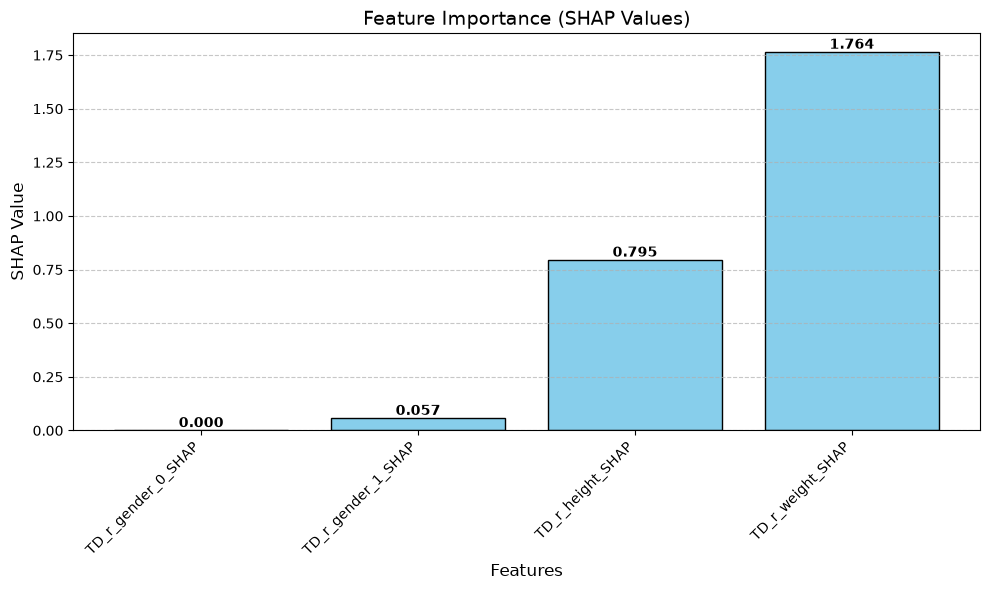

In [10]:
# Generate prediction using some data rows and model rank

prediction = aml.predict(df, rank=1)

In [11]:
prediction

automl_id,Prediction,Prob_2,Prob_4,Prob_3,Prob_5,bmi
25,5,0.0020313401234752634,0.04151822221717798,0.21129770271296042,0.7451527349463863,5
37,2,0.5926843101263635,0.0014651388747475304,0.40530364826722265,0.0005469027316663997,2
41,2,0.793110642570128,0.00038464299709086976,0.2062826502970939,0.00022206413568714444,2
45,5,0.00012275139068064082,0.0007400378921810279,0.0001938072228027949,0.9989434034943354,5
53,5,0.00017550493588334399,0.20106826345585907,0.005516192322801513,0.7932400392854562,5
57,5,0.011801500007271178,0.01921955311367659,0.21792729778844194,0.7510516490906103,5
12,4,0.003913665985518322,0.7277373806812655,0.26452831848618696,0.003820634847029305,4
20,3,0.001163508132230619,0.005450432857268789,0.9921006352874953,0.0012854237230053567,3
24,5,0.0008733359006126145,0.19707495078724113,0.19869144257275081,0.6033602707393955,5
28,5,0.01199714865981499,0.06288344344752733,0.21451828076480867,0.710601127127849,5


In [12]:
# Generate performance metrics

performance_metric = aml.evaluate(df, rank=1)

In [13]:
performance_metric


############ output_data Output ############

   SeqNum              Metric  MetricValue
0       3        Micro-Recall     0.804000
1       5     Macro-Precision     0.506195
2       6        Macro-Recall     0.559981
3       7            Macro-F1     0.529438
4       9     Weighted-Recall     0.804000
5      10         Weighted-F1     0.780990
6       8  Weighted-Precision     0.764618
7       4            Micro-F1     0.804000
8       2     Micro-Precision     0.804000
9       1            Accuracy     0.804000


############ result Output ############

       Prediction  Mapping  CLASS_1  CLASS_2  CLASS_3  CLASS_4  CLASS_5  CLASS_6  Precision    Recall        F1  Support
SeqNum                                                                                                                  
1               1  CLASS_2        0        0        0        0        0        0   0.000000  0.000000  0.000000       22
4               4  CLASS_5        0        0        0       10      113   

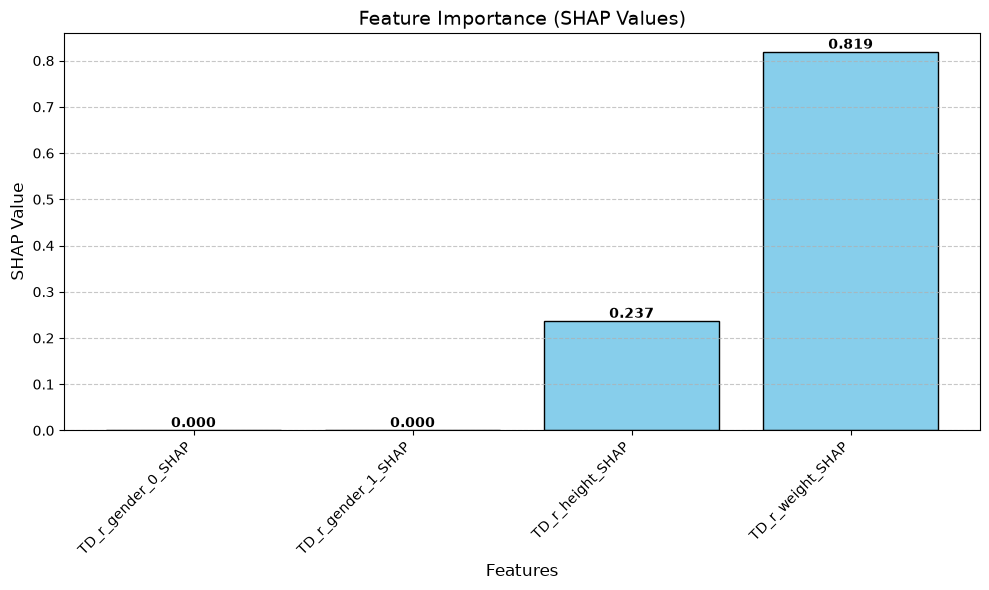

In [14]:
# Generate prediction using data and model rank

prediction = aml.predict(df, rank=3)

In [15]:
prediction

automl_id,Prediction,Prob_2,Prob_4,Prob_3,Prob_5,bmi
24,4,0.1273308295880382,0.38303511031661297,0.18602324831139802,0.30361081178395083,5
36,3,0.09814072279063493,0.2946482863925012,0.48616126776152374,0.12104972305534015,4
40,3,0.2324135465821482,0.22675050434337882,0.41501443934148724,0.12582150973298584,2
44,3,0.22472146957786931,0.030952993729037447,0.5091418810327126,0.2351836556603806,3
52,3,0.07885024243409948,0.041277410456999376,0.8371852632802327,0.04268708382866862,1
56,5,0.03756431114290719,0.15002567226958397,0.006904196588225449,0.8055058199992835,5
13,3,0.22472146957786931,0.030952993729037447,0.5091418810327126,0.2351836556603806,3
21,5,0.17307851446773112,0.27791389413807915,0.13631485665020227,0.4126927347439875,5
25,4,0.12621166870201866,0.48514480229695045,0.08770127239904645,0.3009422566019845,5
29,3,0.10295989663331767,0.3519128498665965,0.4181334162949368,0.12699383720514903,3


In [16]:
# Generate performance metrics

performance_metric = aml.evaluate(df, rank=3)

In [17]:
performance_metric


############ output_data Output ############

   SeqNum              Metric  MetricValue
0       3        Micro-Recall     0.584000
1       5     Macro-Precision     0.358742
2       6        Macro-Recall     0.387977
3       7            Macro-F1     0.337109
4       9     Weighted-Recall     0.584000
5      10         Weighted-F1     0.556887
6       8  Weighted-Precision     0.592885
7       4            Micro-F1     0.584000
8       2     Micro-Precision     0.584000
9       1            Accuracy     0.584000


############ result Output ############

       Prediction  Mapping  CLASS_1  CLASS_2  CLASS_3  CLASS_4  CLASS_5  CLASS_6  Precision    Recall        F1  Support
SeqNum                                                                                                                  
1               1  CLASS_2        0        0        0        0        0        0   0.000000  0.000000  0.000000       22
0               0  CLASS_1        0        0        0        0        0   

## <b><span style='color:#F1A424'>| 2.</span> Loading Deployed Models - 'BMI_mixed_models' </b>

### <b><span style='color:#F1A424'>| 2.1.</span> Loading Model </b>

In [18]:
# Loading models

models_2 = aml.load('BMI_mixed_models')

In [19]:
models_2

,RANK,MODEL_ID,FEATURE_SELECTION,ACCURACY,MICRO-PRECISION,MICRO-RECALL,MICRO-F1,MACRO-PRECISION,MACRO-RECALL,MACRO-F1,WEIGHTED-PRECISION,WEIGHTED-RECALL,WEIGHTED-F1,DATA_TABLE
0,1,XGBOOST_3,pca,0.727273,0.727273,0.727273,0.727273,0.793245,0.676818,0.690056,0.773201,0.727273,0.723600,automl__bmi_pca_179281915316579
1,2,XGBOOST_5,pca,0.625000,0.625000,0.625000,0.625000,0.581961,0.584091,0.573724,0.631795,0.625000,0.618463,automl__bmi_pca_179281915316579


### <b><span style='color:#F1A424'>| 2.2.</span> Generating Prediction & Performance Metrics</b>

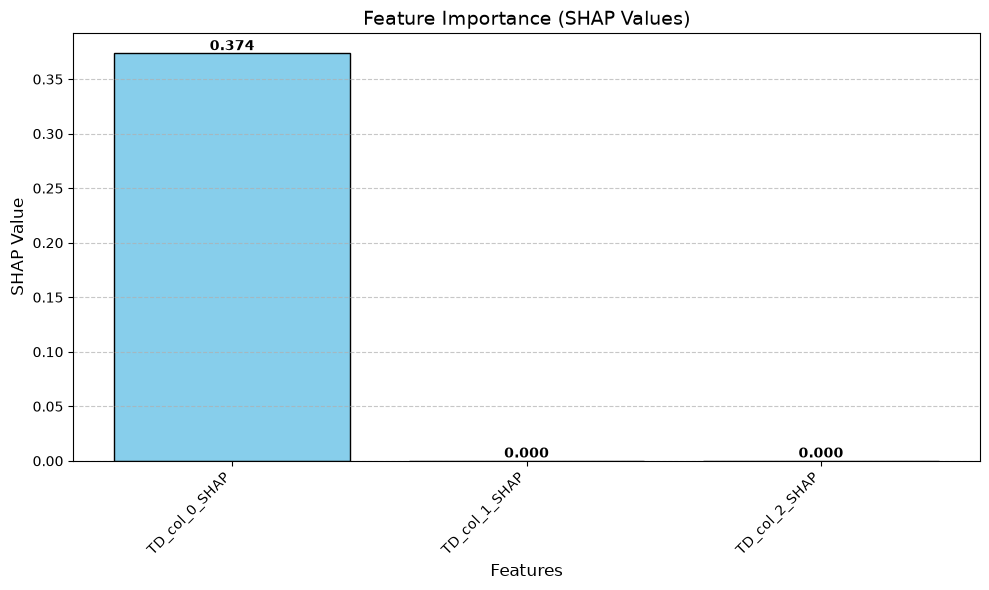

In [20]:
# Generate prediction using data and model rank

prediction = aml.predict(df.iloc[:80], rank=2)

In [21]:
prediction

automl_id,Prediction,Prob_2,Prob_4,Prob_3,Prob_5,bmi
24,2,0.3611866443437039,0.11358127266150704,0.36017237342791947,0.1650597095668696,2
36,2,0.400097271355177,0.10651662898401748,0.3428241417611856,0.1505619578996199,1
40,5,0.11061461204442427,0.11806801075669333,0.2132954798080283,0.5580218973908541,5
44,5,0.11061461204442427,0.11806801075669333,0.2132954798080283,0.5580218973908541,5
52,5,0.11061461204442427,0.11806801075669333,0.2132954798080283,0.5580218973908541,5
56,2,0.400097271355177,0.10651662898401748,0.3428241417611856,0.1505619578996199,2
48,2,0.400097271355177,0.10651662898401748,0.3428241417611856,0.1505619578996199,3
28,4,0.11548677260025153,0.4860611589379574,0.2551899064814675,0.14326216198032346,3
20,4,0.11548677260025153,0.4860611589379574,0.2551899064814675,0.14326216198032346,4
12,5,0.11061461204442427,0.11806801075669333,0.2132954798080283,0.5580218973908541,5


In [22]:
# Generate performance metrics

performance_metric = aml.evaluate(df.iloc[:80], rank=2)

In [23]:
performance_metric


############ output_data Output ############

   SeqNum              Metric  MetricValue
0       3        Micro-Recall     0.737500
1       5     Macro-Precision     0.467437
2       6        Macro-Recall     0.490669
3       7            Macro-F1     0.457614
4       9     Weighted-Recall     0.737500
5      10         Weighted-F1     0.713048
6       8  Weighted-Precision     0.729359
7       4            Micro-F1     0.737500
8       2     Micro-Precision     0.737500
9       1            Accuracy     0.737500


############ result Output ############

       Prediction  Mapping  CLASS_1  CLASS_2  CLASS_3  CLASS_4  CLASS_5  CLASS_6  Precision    Recall        F1  Support
SeqNum                                                                                                                  
1               1  CLASS_2        0        0        0        0        0        0   0.000000  0.000000  0.000000        2
4               4  CLASS_5        0        0        1        4       20   

## <b><span style='color:#F1A424'>| 3.</span> Loading Deployed Models - 'BMI_range_models' </b>

### <b><span style='color:#F1A424'>| 3.1.</span> Loading Model</b>

In [24]:
# Creating another AutoML object

obj=ctx.AutoML()

In [25]:
# Loading models

models_3 = obj.load('BMI_range_models')

In [26]:
models_3

,RANK,MODEL_ID,FEATURE_SELECTION,ACCURACY,MICRO-PRECISION,MICRO-RECALL,MICRO-F1,MACRO-PRECISION,MACRO-RECALL,MACRO-F1,WEIGHTED-PRECISION,WEIGHTED-RECALL,WEIGHTED-F1,DATA_TABLE
0,1,XGBOOST_2,rfe,0.636364,0.636364,0.636364,0.636364,0.604762,0.543636,0.521214,0.633658,0.636364,0.598117,automl__bmi_rfe_179283147807654
1,2,XGBOOST_5,pca,0.625000,0.625000,0.625000,0.625000,0.581961,0.584091,0.573724,0.631795,0.625000,0.618463,automl__bmi_pca_179281774700248
2,3,XGBOOST_4,pca,0.602273,0.602273,0.602273,0.602273,0.555742,0.561364,0.556056,0.601756,0.602273,0.599383,automl__bmi_pca_179281774700248
3,4,XGBOOST_1,rfe,0.340909,0.340909,0.340909,0.340909,0.085227,0.250000,0.127119,0.116219,0.340909,0.173344,automl__bmi_rfe_179283147807654


### <b><span style='color:#F1A424'>| 3.2.</span> Generating Prediction & Performance Metrics</b>

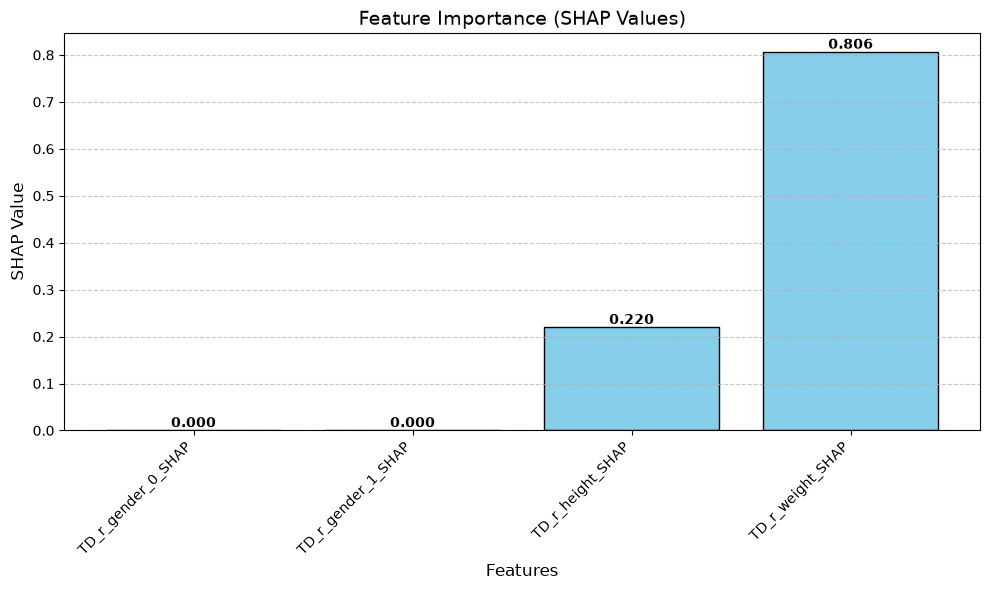

In [27]:
# Generate prediction using data and model rank

prediction = obj.predict(df.iloc[:80], rank=1)

In [28]:
prediction

automl_id,Prediction,Prob_2,Prob_4,Prob_3,Prob_5,bmi
24,3,0.2324135465821482,0.22675050434337882,0.41501443934148724,0.12582150973298584,2
36,3,0.07885024243409948,0.041277410456999376,0.8371852632802327,0.04268708382866862,1
40,5,0.03756431114290719,0.15002567226958397,0.006904196588225449,0.8055058199992835,5
44,5,0.043231272201632476,0.02085605110332351,0.008888053991070838,0.9270246227039731,5
52,5,0.07760430096398564,0.04284563832352485,0.018734857955538985,0.8608152027569506,5
56,3,0.17821341321291714,0.15037764789612734,0.5749297059251091,0.09647923296584644,2
48,4,0.06140851842278027,0.6853047035491597,0.17754366205188904,0.07574311597617094,3
28,3,0.22472146957786931,0.030952993729037447,0.5091418810327126,0.2351836556603806,3
20,3,0.09814072279063493,0.2946482863925012,0.48616126776152374,0.12104972305534015,4
12,4,0.1273308295880382,0.38303511031661297,0.18602324831139802,0.30361081178395083,5


In [29]:
# Generate performance metrics

performance_metric = obj.evaluate(df.iloc[:80], rank=1)

In [30]:
performance_metric


############ output_data Output ############

   SeqNum              Metric  MetricValue
0       3        Micro-Recall     0.562500
1       5     Macro-Precision     0.396779
2       6        Macro-Recall     0.361929
3       7            Macro-F1     0.341948
4       9     Weighted-Recall     0.562500
5      10         Weighted-F1     0.546972
6       8  Weighted-Precision     0.599713
7       4            Micro-F1     0.562500
8       2     Micro-Precision     0.562500
9       1            Accuracy     0.562500


############ result Output ############

       Prediction  Mapping  CLASS_1  CLASS_2  CLASS_3  CLASS_4  CLASS_5  CLASS_6  Precision    Recall        F1  Support
SeqNum                                                                                                                  
3               3  CLASS_4        3        1        6       11       11        2   0.323529  0.785714  0.458333       14
2               2  CLASS_3        0        1        2        0        0   

In [31]:
ctx.remove_context()

True